# 04 – Khai phá luật kết hợp: Apriori và Multilevel
Đầu vào: `outputs/basket_items.csv.gz`, `outputs/household_base.csv`, `outputs/split.csv` (notebook 02).
Quy ước:
1. **Giao dịch = 1 giỏ hàng**, item = nhóm hàng. Chỉ dùng giỏ của các hộ **không thuộc tập test** để tìm luật.
2. **Phương pháp 1 – Apriori (cơ bản):** một cấp (commodity), một ngưỡng support 2%.
3. **Phương pháp 2 – Multilevel AR (nâng cao):** chạy Apriori trên 3 cấp của cây sản phẩm với **support giảm dần** (department 10% → commodity 2% → sub-commodity 0,5%), sau đó **loại luật dư thừa** của cấp con so với luật cấp cha.
4. Cả hai dùng chung confidence ≥ 0,3, lift > 1, tối đa 3 item/luật.
5. **Chọn 3 luật tốt nhất mỗi phương pháp** theo mức liên quan với biến mục tiêu `redeemed`, tính **chỉ trên hộ train** (|hệ số Spearman| giữa đặc trưng của luật và nhãn). Thêm bộ đối chứng: 3 luật có lift cao nhất.
6. **Đặc trưng mới** của luật X → Y cho mỗi hộ = tỷ lệ giỏ của hộ chứa đủ X ∪ Y (0–1). Tính cho cả 1.584 hộ vì bước này không dùng nhãn.

In [1]:
# Chạy trên Google Colab: kết nối Drive và chuyển vào thư mục notebooks của dự án (máy cá nhân thì bỏ qua)
import os
try:
    from google.colab import drive
    drive.mount('/content/drive')
    os.chdir('/content/drive/MyDrive/DM_Nhom3_Final/notebooks')  # sửa nếu để thư mục dự án ở chỗ khác
except ImportError:
    pass
print(os.getcwd())

/home/claude/DM_Nhom3_Final/notebooks


In [2]:
import sys, warnings, time
sys.path.append('../src'); warnings.filterwarnings('ignore')
try:
    import mlxtend
except ImportError:
    %pip install -q mlxtend
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from mlxtend.frequent_patterns import apriori, association_rules
from scipy.stats import spearmanr
from style import setup, save, vn, BLUE, ORANGE, AQUA, GRAY, INK, INK2
setup(); pd.set_option('display.width', 220); pd.set_option('display.max_colwidth', 80)

bi = pd.read_csv('../outputs/basket_items.csv.gz')
hb = pd.read_csv('../outputs/household_base.csv')
split = pd.read_csv('../outputs/split.csv')
y = hb.set_index('household_key').redeemed
train_hh = split.loc[split.set=='train','household_key'].values
test_hh  = split.loc[split.set=='test','household_key'].values
print('Giỏ hàng:', vn(bi.BASKET_ID.nunique()), '| hộ trong bảng giỏ:', vn(bi.household_key.nunique()))
print('Hộ train / test:', len(train_hh), '/', len(test_hh))

Giỏ hàng: 250.942 | hộ trong bảng giỏ: 2.500
Hộ train / test: 1267 / 317


## 1. Ma trận giỏ hàng × item cho 3 cấp
Mỗi giỏ là một dòng, mỗi item là một cột (True nếu giỏ có item đó). Ma trận dựng cho **toàn bộ** giỏ; khi tìm luật chỉ lấy các dòng thuộc tập khai phá (giỏ của hộ không thuộc test). Để tiết kiệm bộ nhớ, chỉ giữ các item có thể vượt ngưỡng support của cấp đó – Apriori cũng loại các item này ngay ở vòng đầu nên kết quả không đổi.

In [3]:
LEVELS = {'DEPARTMENT': 0.10, 'COMMODITY_DESC': 0.02, 'SUB_COMMODITY_DESC': 0.005}
LV = {'DEPARTMENT': 'Department', 'COMMODITY_DESC': 'Commodity', 'SUB_COMMODITY_DESC': 'Sub-commodity'}
baskets = bi.groupby('BASKET_ID').household_key.first()
b_hh = baskets.values                                          # hộ của từng giỏ
mine_mask = ~np.isin(b_hh, test_hh)                            # tập khai phá = giỏ của hộ không thuộc test
bcode = pd.Categorical(bi.BASKET_ID, categories=baskets.index).codes
n_mine = mine_mask.sum()
print(f'Tập khai phá: {vn(n_mine)} giỏ ({mine_mask.mean():.1%}), bỏ {vn((~mine_mask).sum())} giỏ của {len(test_hh)} hộ test')

mats = {}
for lvl, s in LEVELS.items():
    sup = bi[np.isin(bi.household_key, test_hh, invert=True)].groupby(lvl).BASKET_ID.nunique() / n_mine
    items = sup[sup >= s].index
    keep = bi[lvl].isin(items).values
    arr = np.zeros((len(baskets), len(items)), dtype=bool)
    arr[bcode[keep], pd.Categorical(bi.loc[keep, lvl], categories=items).codes] = True
    mats[lvl] = pd.DataFrame(arr, columns=items)
    print(f'{LV[lvl]:<14} tổng {bi[lvl].nunique():>5} item, đạt support ≥ {s:.1%}: {len(items)} item')

Tập khai phá: 204.258 giỏ (81.4%), bỏ 46.684 giỏ của 317 hộ test


Department     tổng    28 item, đạt support ≥ 10.0%: 7 item


Commodity      tổng   299 item, đạt support ≥ 2.0%: 111 item


Sub-commodity  tổng  2355 item, đạt support ≥ 0.5%: 425 item


## 2. Phương pháp 1 – Apriori (commodity, support ≥ 2%)

In [4]:
MIN_CONF, MAX_LEN = 0.3, 3
def run_apriori(lvl, minsup):
    t = time.time()
    fi = apriori(mats[lvl][mine_mask], min_support=minsup, use_colnames=True, max_len=MAX_LEN, low_memory=True)
    r = association_rules(fi, metric='confidence', min_threshold=MIN_CONF)
    r = r[r.lift > 1].copy(); r['level'] = lvl
    print(f'{LV[lvl]:<14} support ≥ {minsup:.1%}: {len(fi):>5} tập phổ biến, {len(r):>5} luật  ({time.time()-t:.0f}s)')
    return fi, r[['antecedents','consequents','support','confidence','lift','level']].reset_index(drop=True)

fi_ap, R_ap = run_apriori('COMMODITY_DESC', 0.02)
R_ap.sort_values('lift', ascending=False).head(10)

Commodity      support ≥ 2.0%:   610 tập phổ biến,   737 luật  (1s)


,antecedents,consequents,support,confidence,lift,level
221,frozenset({PASTA SAUCE}),frozenset({DRY NOODLES/PASTA}),0.025796,0.547031,9.696729,COMMODITY_DESC
220,frozenset({DRY NOODLES/PASTA}),frozenset({PASTA SAUCE}),0.025796,0.457259,9.696729,COMMODITY_DESC
186,frozenset({CHEESES}),frozenset({DELI MEATS}),0.028577,0.633493,9.136194,COMMODITY_DESC
185,frozenset({DELI MEATS}),frozenset({CHEESES}),0.028577,0.412130,9.136194,COMMODITY_DESC
103,frozenset({BEANS - CANNED GLASS & MW}),frozenset({VEGETABLES - SHELF STABLE}),0.020239,0.523623,5.803890,COMMODITY_DESC
218,frozenset({DRY BN/VEG/POTATO/RICE}),frozenset({VEGETABLES - SHELF STABLE}),0.021507,0.401848,4.454126,COMMODITY_DESC
266,frozenset({FRUIT - SHELF STABLE}),frozenset({VEGETABLES - SHELF STABLE}),0.020978,0.397901,4.410383,COMMODITY_DESC
223,frozenset({DRY NOODLES/PASTA}),frozenset({VEGETABLES - SHELF STABLE}),0.022305,0.395383,4.382471,COMMODITY_DESC
215,frozenset({DINNER MXS:DRY}),frozenset({VEGETABLES - SHELF STABLE}),0.020964,0.387476,4.294830,COMMODITY_DESC
611,"frozenset({CHEESE, BEEF})",frozenset({VEGETABLES - SHELF STABLE}),0.024151,0.377371,4.182827,COMMODITY_DESC


## 3. Phương pháp 2 – Multilevel AR (support giảm dần theo cấp)
Chạy Apriori riêng cho từng cấp với ngưỡng 10% / 2% / 0,5%. Cấp càng chi tiết, mỗi item càng ít xuất hiện nên ngưỡng phải thấp hơn – nếu dùng chung 2% cho cấp sub-commodity thì phần lớn nhóm hàng con bị loại (đuôi dài Pareto ở Bước 1).

**Loại luật dư thừa** (Han, Kamber & Pei, mục 7.2.1): một luật cấp con là dư thừa nếu có luật "cha" (thay mỗi item bằng nhóm cha của nó) và support, confidence của luật con xấp xỉ giá trị **kỳ vọng** suy ra từ luật cha. Ví dụ luật cha *sữa → bánh mì* (support 8%, conf 70%), nếu *sữa tươi* chiếm 1/4 lượng *sữa* thì luật *sữa tươi → bánh mì* kỳ vọng có support 2%, conf 70%; nếu thực tế đúng như vậy thì luật con không mang thêm thông tin. Ở đây dùng sai lệch tương đối ≤ 20% cho cả support và confidence.

In [5]:
fi_ml, R_lv = {}, {}
for lvl, s in LEVELS.items():
    fi_ml[lvl], R_lv[lvl] = run_apriori(lvl, s)

# support của từng item (trên tập khai phá) và bảng item -> nhóm cha
isup = {lvl: mats[lvl][mine_mask].mean() for lvl in LEVELS}
parent = {'COMMODITY_DESC': bi.groupby('COMMODITY_DESC').DEPARTMENT.agg(lambda s: s.mode()[0]),
          'SUB_COMMODITY_DESC': bi.groupby('SUB_COMMODITY_DESC').COMMODITY_DESC.agg(lambda s: s.mode()[0])}
up = {'COMMODITY_DESC': 'DEPARTMENT', 'SUB_COMMODITY_DESC': 'COMMODITY_DESC'}

def mark_redundant(lvl, tol=0.2):
    R, P = R_lv[lvl], R_lv[up[lvl]]
    pidx = {(a, c): (s, cf) for a, c, s, cf in zip(P.antecedents, P.consequents, P.support, P.confidence)}
    red = []
    for a, c, s, cf in zip(R.antecedents, R.consequents, R.support, R.confidence):
        pa = frozenset(parent[lvl][i] for i in a); pc = frozenset(parent[lvl][i] for i in c)
        if len(pa) < len(a) or len(pc) < len(c) or pa & pc or (pa, pc) not in pidx:
            red.append(False); continue               # không có luật cha tương ứng -> giữ
        ps, pcf = pidx[(pa, pc)]
        ratio = lambda i: isup[lvl][i] / psup_ratio[up[lvl]][parent[lvl][i]]
        exp_s = ps * np.prod([ratio(i) for i in a | c]); exp_cf = pcf * np.prod([ratio(i) for i in c])
        red.append(abs(s/exp_s - 1) <= tol and abs(cf/exp_cf - 1) <= tol)
    return np.array(red)

# support của item cấp cha trên tập khai phá (kể cả item dưới ngưỡng, nên tính trực tiếp từ bảng giỏ)
bm = bi[np.isin(bi.household_key, test_hh, invert=True)]
psup_ratio = {l: bm.groupby(l).BASKET_ID.nunique() / n_mine for l in ['DEPARTMENT', 'COMMODITY_DESC']}

parts = [R_lv['DEPARTMENT'].assign(redundant=False)]
for lvl in ['COMMODITY_DESC', 'SUB_COMMODITY_DESC']:
    rd = mark_redundant(lvl); parts.append(R_lv[lvl].assign(redundant=rd))
    print(f'{LV[lvl]:<14} {len(rd):>5} luật, dư thừa so với cấp cha: {rd.sum():>4} ({rd.mean():.1%})')
R_ml_all = pd.concat(parts, ignore_index=True)
R_ml = R_ml_all[~R_ml_all.redundant].drop(columns='redundant').reset_index(drop=True)
print('Multilevel sau khi loại dư thừa:', len(R_ml), 'luật;', R_ml.level.map(LV).value_counts().to_dict())

Department     support ≥ 10.0%:    25 tập phổ biến,    43 luật  (0s)


Commodity      support ≥ 2.0%:   610 tập phổ biến,   737 luật  (1s)


Sub-commodity  support ≥ 0.5%:  1534 tập phổ biến,   689 luật  (3s)


Commodity        737 luật, dư thừa so với cấp cha:    4 (0.5%)
Sub-commodity    689 luật, dư thừa so với cấp cha:  208 (30.2%)
Multilevel sau khi loại dư thừa: 1257 luật; {'Commodity': 733, 'Sub-commodity': 481, 'Department': 43}


### Tổng hợp số luật của hai phương pháp

In [6]:
summary = pd.DataFrame([
    {'Phương pháp': 'Apriori', 'Cấp': 'Commodity', 'Min support': '2%', 'Tập phổ biến': len(fi_ap), 'Số luật': len(R_ap)},
    *[{'Phương pháp': 'Multilevel', 'Cấp': LV[l], 'Min support': f'{s:.1%}'.replace('.0%','%'), 'Tập phổ biến': len(fi_ml[l]),
       'Số luật': len(R_lv[l]), 'Luật dư thừa': int(R_ml_all[(R_ml_all.level==l)].redundant.sum()),
       'Luật giữ lại': int((R_ml.level==l).sum())} for l, s in LEVELS.items()]])
summary.to_csv('../outputs/bang_so_luat.csv', index=False); summary

,Phương pháp,Cấp,Min support,Tập phổ biến,Số luật,Luật dư thừa,Luật giữ lại
0,Apriori,Commodity,2%,610,737,NaN,NaN
1,Multilevel,Department,10%,25,43,0.0,43.0
2,Multilevel,Commodity,2%,610,737,4.0,733.0
3,Multilevel,Sub-commodity,0.5%,1534,689,208.0,481.0


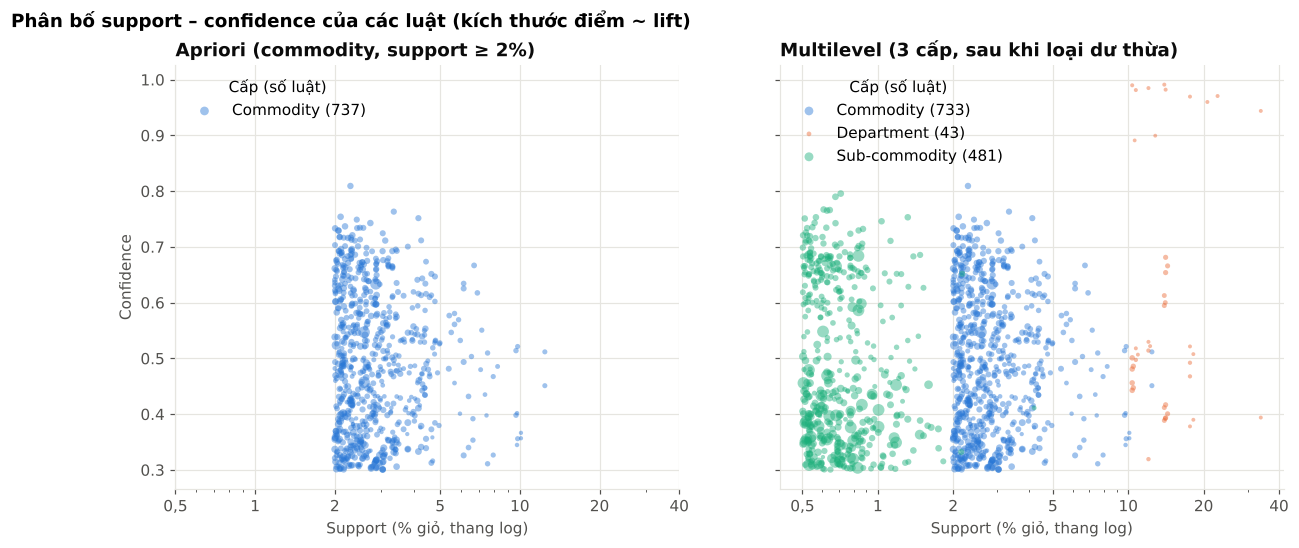

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for a, (name, R) in zip(ax, [('Apriori (commodity, support ≥ 2%)', R_ap), ('Multilevel (3 cấp, sau khi loại dư thừa)', R_ml)]):
    cols = {'DEPARTMENT': ORANGE, 'COMMODITY_DESC': BLUE, 'SUB_COMMODITY_DESC': AQUA}
    for lvl, g in R.groupby('level'):
        a.scatter(g.support*100, g.confidence, s=np.clip(g.lift*6, 4, 60), alpha=0.45, color=cols[lvl], label=f'{LV[lvl]} ({len(g)})', edgecolor='none')
    a.set(xscale='log', xlabel='Support (% giỏ, thang log)', title=name); a.legend(loc='upper left', title='Cấp (số luật)')
    a.set_xticks([0.5, 1, 2, 5, 10, 20, 40]); a.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:g}'.replace('.', ','))); a.xaxis.set_minor_formatter(plt.NullFormatter())
ax[0].set_ylabel('Confidence')
fig.suptitle('Phân bố support – confidence của các luật (kích thước điểm ~ lift)', x=0.01, ha='left', fontweight='bold')
save(fig, 'H11_phan_bo_luat')

## 4. Chọn 3 luật tốt nhất mỗi phương pháp
Với mỗi luật, tính đặc trưng ở cấp hộ (tỷ lệ giỏ chứa X ∪ Y), rồi đo |Spearman| với nhãn `redeemed` **trên 1.267 hộ train**. Luật được xếp theo mức liên quan này. Hai luật có cùng tập item (X → Y và Y → X) cho cùng một đặc trưng nên chỉ giữ một; luật có đặc trưng tương quan > 0,9 với luật đã chọn cũng bỏ qua để 3 đặc trưng không trùng thông tin.

In [8]:
def rule_feature(lvl, items):
    pres = mats[lvl][list(items)].all(axis=1).values
    return pd.Series(pres, index=b_hh).groupby(level=0).mean()

def score_rules(R):
    feats, sc = [], []
    ytr = y.loc[train_hh]
    for lvl, a, c in zip(R.level, R.antecedents, R.consequents):
        f = rule_feature(lvl, a | c); feats.append(f)
        sc.append(abs(spearmanr(f.reindex(train_hh).fillna(0), ytr).correlation))
    return R.assign(relevance=sc), feats

def pick(R, feats, by, k=3):
    chosen, out = [], []
    for i in R.sort_values([by, 'confidence'], ascending=False, kind='stable').index:   # X→Y và Y→X cùng điểm: lấy chiều có confidence cao hơn
        key = R.at[i,'antecedents'] | R.at[i,'consequents']
        f = feats[i].reindex(y.index).fillna(0)
        if any(key == R.at[j,'antecedents'] | R.at[j,'consequents'] for j in chosen): continue
        if any(abs(np.corrcoef(f, feats[j].reindex(y.index).fillna(0))[0,1]) > 0.9 for j in chosen): continue
        chosen.append(i)
        if len(chosen) == k: break
    return chosen

t = time.time()
R_ap, F_ap = score_rules(R_ap); R_ml, F_ml = score_rules(R_ml)
print(f'Đã tính đặc trưng cho {len(R_ap)+len(R_ml)} luật ({time.time()-t:.0f}s)')
fmt = lambda s: ', '.join(sorted(s))
def show(R, idx, meth, crit):
    d = R.loc[idx].copy(); d.insert(0, 'Phương pháp', meth); d.insert(1, 'Tiêu chí', crit)
    d['Cấp'] = d.level.map(LV); d['Luật'] = [f'{{{fmt(a)}}} → {{{fmt(c)}}}' for a, c in zip(d.antecedents, d.consequents)]
    return d[['Phương pháp','Tiêu chí','Cấp','Luật','support','confidence','lift','relevance']]
best_ap, best_ml = pick(R_ap, F_ap, 'relevance'), pick(R_ml, F_ml, 'relevance')
lift_ap, lift_ml = pick(R_ap, F_ap, 'lift'), pick(R_ml, F_ml, 'lift')
top = pd.concat([show(R_ap, best_ap, 'Apriori', 'Liên quan y'), show(R_ml, best_ml, 'Multilevel', 'Liên quan y'),
                 show(R_ap, lift_ap, 'Apriori', 'Lift cao nhất'), show(R_ml, lift_ml, 'Multilevel', 'Lift cao nhất')], ignore_index=True)
top.to_csv('../outputs/bang_3_luat_tot_nhat.csv', index=False)
top.round(3)

Đã tính đặc trưng cho 1994 luật (10s)


,Phương pháp,Tiêu chí,Cấp,Luật,support,confidence,lift,relevance
0,Apriori,Liên quan y,Commodity,{VEGETABLES - SHELF STABLE} → {TROPICAL FRUIT},0.028,0.305,2.340,0.259
1,Apriori,Liên quan y,Commodity,{CRACKERS/MISC BKD FD} → {TROPICAL FRUIT},0.028,0.312,2.393,0.249
2,Apriori,Liên quan y,Commodity,{FRZN VEGETABLE/VEG DSH} → {FLUID MILK PRODUCTS},0.026,0.501,1.816,0.247
3,Multilevel,Liên quan y,Department,{PRODUCE} → {GROCERY},0.338,0.944,1.099,0.281
4,Multilevel,Liên quan y,Department,"{DRUG GM, PRODUCE} → {GROCERY}",0.176,0.969,1.129,0.272
5,Multilevel,Liên quan y,Sub-commodity,"{BANANAS, YOGURT NOT MULTI-PACKS} → {FLUID MILK WHITE ONLY}",0.012,0.651,2.662,0.260
6,Apriori,Lift cao nhất,Commodity,{PASTA SAUCE} → {DRY NOODLES/PASTA},0.026,0.547,9.697,0.035
7,Apriori,Lift cao nhất,Commodity,{CHEESES} → {DELI MEATS},0.029,0.633,9.136,0.135
8,Apriori,Lift cao nhất,Commodity,{BEANS - CANNED GLASS & MW} → {VEGETABLES - SHELF STABLE},0.020,0.524,5.804,0.160
9,Multilevel,Lift cao nhất,Sub-commodity,{FROSTING} → {LAYER CAKE MIX},0.008,0.684,47.920,0.079


## 5. So sánh độ bao phủ (coverage)
Coverage của một bộ luật = tỷ lệ giỏ hàng chứa đủ X ∪ Y của **ít nhất một** luật trong bộ. Tính trên toàn bộ 250.942 giỏ.

In [9]:
def presence(R, idx):
    return np.column_stack([mats[R.at[i,'level']][list(R.at[i,'antecedents'] | R.at[i,'consequents'])].all(axis=1).values for i in idx])
rows = []
sets = {}
for meth, crit, R, idx in [('Apriori','Liên quan y',R_ap,best_ap), ('Multilevel','Liên quan y',R_ml,best_ml),
                           ('Apriori','Lift cao nhất',R_ap,lift_ap), ('Multilevel','Lift cao nhất',R_ml,lift_ml)]:
    P = presence(R, idx); cov = P.any(axis=1); sets[(meth, crit)] = cov
    rows.append({'Phương pháp': meth, 'Tiêu chí chọn': crit, 'Luật 1': P[:,0].mean(), 'Luật 2': P[:,1].mean(), 'Luật 3': P[:,2].mean(),
                 'Coverage (≥1 luật)': cov.mean(), 'Số giỏ được phủ': int(cov.sum())})
cov_tab = pd.DataFrame(rows)
for crit in ['Liên quan y', 'Lift cao nhất']:
    a, m = sets[('Apriori', crit)], sets[('Multilevel', crit)]
    print(f'{crit:<14} giao: {(a&m).mean():.2%} | chỉ Apriori: {(a&~m).mean():.2%} | chỉ Multilevel: {(m&~a).mean():.2%} | hợp: {(a|m).mean():.2%}')
cov_tab.to_csv('../outputs/bang_coverage.csv', index=False)
cov_tab.style.format({c: '{:.2%}' for c in ['Luật 1','Luật 2','Luật 3','Coverage (≥1 luật)']})

Liên quan y    giao: 5.98% | chỉ Apriori: 0.43% | chỉ Multilevel: 27.50% | hợp: 33.92%
Lift cao nhất  giao: 0.51% | chỉ Apriori: 6.18% | chỉ Multilevel: 1.48% | hợp: 8.18%


,Phương pháp,Tiêu chí chọn,Luật 1,Luật 2,Luật 3,Coverage (≥1 luật),Số giỏ được phủ
0,Apriori,Liên quan y,2.74%,2.79%,2.52%,6.41%,16092
1,Multilevel,Liên quan y,33.49%,17.68%,1.24%,33.49%,84028
2,Apriori,Lift cao nhất,2.54%,2.84%,1.98%,6.69%,16796
3,Multilevel,Lift cao nhất,0.84%,0.68%,0.52%,2.00%,5010


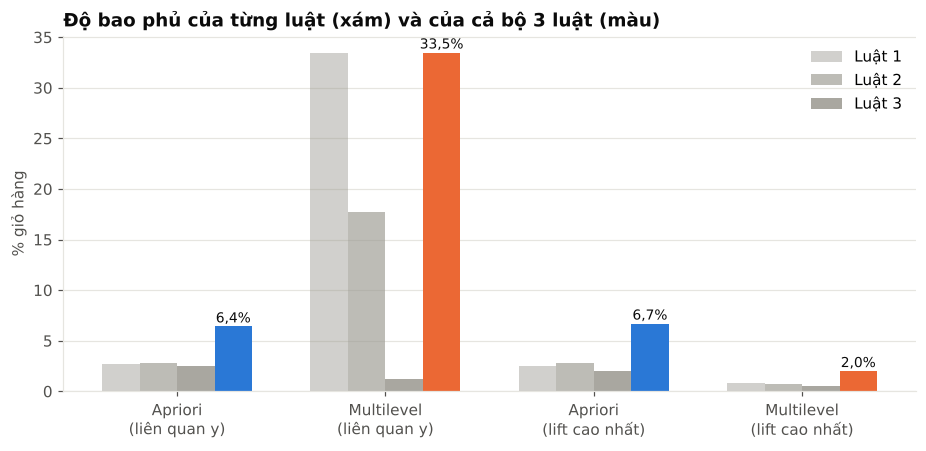

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.2))
lab = [f'{r["Phương pháp"]}\n({r["Tiêu chí chọn"].lower()})' for _, r in cov_tab.iterrows()]
x = np.arange(len(cov_tab)); w = 0.18
for k, (c, col) in enumerate(zip(['Luật 1','Luật 2','Luật 3'], [GRAY]*3)):
    ax.bar(x + (k-1.5)*w, cov_tab[c]*100, w, color=col, alpha=0.45 + 0.2*k, label=c)
b = ax.bar(x + 1.5*w, cov_tab['Coverage (≥1 luật)']*100, w, color=[BLUE, ORANGE, BLUE, ORANGE])
for r, v in zip(b, cov_tab['Coverage (≥1 luật)']): ax.text(r.get_x()+r.get_width()/2, v*100+0.4, f'{v*100:.1f}%'.replace('.',','), ha='center', fontsize=9, color=INK)
ax.set_xticks(x, lab); ax.set_ylabel('% giỏ hàng'); ax.grid(axis='x', visible=False); ax.legend(loc='upper right')
ax.set_title('Độ bao phủ của từng luật (xám) và của cả bộ 3 luật (màu)')
save(fig, 'H12_coverage')

## 6. Tạo đặc trưng mới cho từng hộ
`ap_r1..ap_r3` từ 3 luật Apriori, `ml_r1..ml_r3` từ 3 luật Multilevel (tiêu chí liên quan y). Bộ đối chứng `apL_r1..3`, `mlL_r1..3` từ 3 luật lift cao nhất. Giá trị = tỷ lệ giỏ của hộ chứa đủ X ∪ Y. Tính cho **cả 1.584 hộ** (không dùng nhãn nên không rò rỉ).

In [11]:
rf_tab = pd.DataFrame(index=hb.household_key)
for p, R, F, idx in [('ap', R_ap, F_ap, best_ap), ('ml', R_ml, F_ml, best_ml), ('apL', R_ap, F_ap, lift_ap), ('mlL', R_ml, F_ml, lift_ml)]:
    for k, i in enumerate(idx, 1):
        rf_tab[f'{p}_r{k}'] = F[i].reindex(rf_tab.index).fillna(0).round(5)
rf_tab.reset_index().to_csv('../outputs/rule_features.csv', index=False)
main = [c for c in rf_tab if c[:3] in ('ap_', 'ml_')]
desc = rf_tab.join(y).groupby('redeemed').mean().T.rename(columns={0:'TB hộ không dùng coupon', 1:'TB hộ dùng coupon'})
desc['Tương quan Spearman (train)'] = [spearmanr(rf_tab.loc[train_hh, c], y.loc[train_hh]).correlation for c in rf_tab]
nonzero = (rf_tab > 0).mean().rename('Tỷ lệ hộ > 0')
desc = desc.join(nonzero)
print(rf_tab.shape); desc.round(4)

(1584, 12)


,TB hộ không dùng coupon,TB hộ dùng coupon,Tương quan Spearman (train),Tỷ lệ hộ > 0
ap_r1,0.0283,0.0551,0.2589,0.6982
ap_r2,0.0304,0.0554,0.2486,0.7077
ap_r3,0.0246,0.0453,0.2466,0.6944
ml_r1,0.3524,0.4670,0.2810,0.9994
ml_r2,0.1859,0.2742,0.2722,0.9893
ml_r3,0.0135,0.0273,0.2598,0.3965
apL_r1,0.0303,0.0345,0.0346,0.7355
apL_r2,0.0305,0.0465,0.1345,0.5865
apL_r3,0.0214,0.0321,0.1605,0.6547
mlL_r1,0.0090,0.0118,0.0786,0.4590


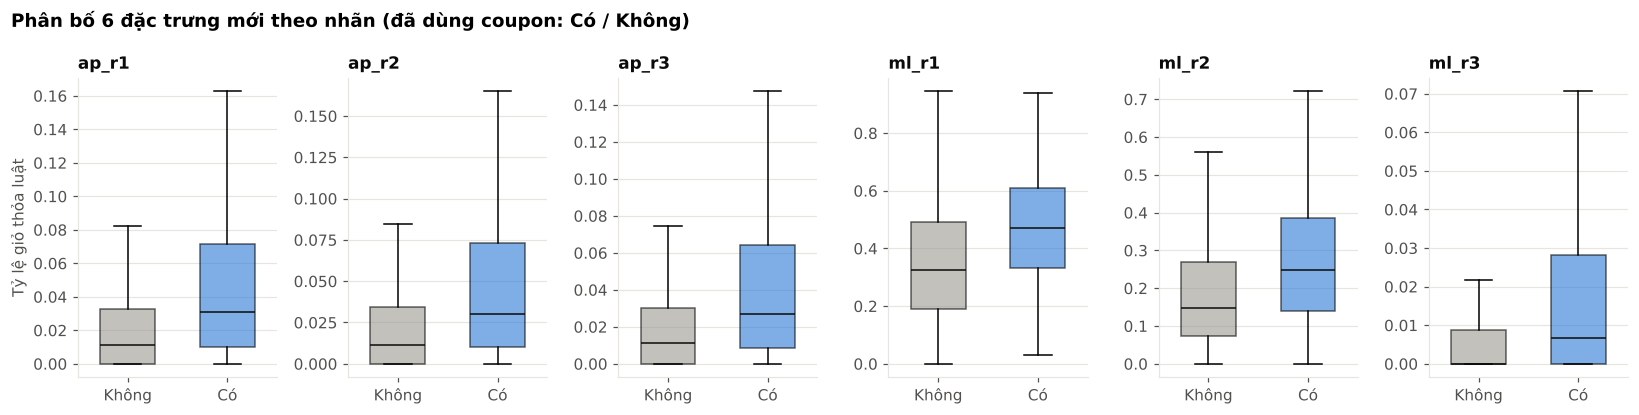

In [12]:
fig, ax = plt.subplots(1, 6, figsize=(15, 3.8), sharey=False)
d = rf_tab.join(y)
for a, c in zip(ax, main):
    parts = [d.loc[d.redeemed==k, c] for k in (0, 1)]
    bp = a.boxplot(parts, widths=0.55, patch_artist=True, showfliers=False, medianprops={'color': INK})
    for patch, col in zip(bp['boxes'], [GRAY, BLUE]): patch.set_facecolor(col); patch.set_alpha(0.6)
    a.set_xticks([1, 2], ['Không', 'Có']); a.set_title(c, fontsize=11); a.grid(axis='x', visible=False)
ax[0].set_ylabel('Tỷ lệ giỏ thỏa luật')
fig.suptitle('Phân bố 6 đặc trưng mới theo nhãn (đã dùng coupon: Có / Không)', x=0.01, ha='left', fontweight='bold')
fig.tight_layout(); save(fig, 'H13_dac_trung_luat_theo_nhan')

**Đầu ra:** `outputs/rule_features.csv`, `bang_so_luat.csv`, `bang_3_luat_tot_nhat.csv`, `bang_coverage.csv`, hình H11–H13.